## 파이썬에서 데이터분석을 하기 위한 필수 Library
### (1) Pandas
- 2008 금융데이터 분석용으로 출발
- 통계와 데이터과학, 머신러닝에서 사용

### (2) Numpy
- 파이썬 기반 수치해석 Library
- 선형대수 연산에 필요한 다차원 배열 연산을 수행하는 다양한 함수 제공

### (3) Matplotlib
- 그래프나 차트 등 그래픽으로 표현하는 파이썬 시각화 도구

### (4) SciPy
- 과학용 연산에 필요한 다양한 패키지를 모아 놓은 Library
- 미적분, 선형대수, 행렬연산, 방정식

### (5) scikit-learn
- 머신러닝 학습을 위한 파이썬 Library
- 회귀분석(regression), 분류(classification), 군집(cluster)



### Pandas / Numpy
Pandas/Numpy는 고급 데이터 분석과 수치 계산 등의 기능을 제공하는 확장 모듈   
Numpy는 수치 계산을 효율적으로 하기 위한 모듈로 다차원 배열과 고수준의 수학 함수를 제공.   
Pandas는 테이블 분석 기능을 제공하는 라이브러리로 CSV파일 등의 데이터를 읽고 원하는 형식으로 변환   


----
### DataFrame
Pandas에서 사용하는 기본 데이터 타입.   
데이터프레임을 정의할 때는 2차원 리스트를 매개변수로 전달.   

### Pandas를 이용하여 데이터프레임 만들기

In [3]:
# 모듈 불러오기
import pandas as pd

In [5]:
# List로 DataFrame 만들기
temp = \
[
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
]

df = pd.DataFrame(temp)
df

,0,1,2
0,10,20,30
1,40,50,60
2,70,80,90


### DataFrame에서 값 추출하기

In [14]:
# 열 기준으로 추출하기
df[0]
df.loc[:,0]

0    10
1    40
2    70
Name: 0, dtype: int64

In [15]:
# 행 기분으로 추출하기
df.loc[0,:]

0    10
1    20
2    30
Name: 0, dtype: int64

In [22]:
# 범위를 정해 열 기준으로 추출하기
df.loc[:,0:1] # Slicing
df.loc[:,[0,1]] # Indexing
df.loc[:,range(0,1+1)] # range 함수

,0,1
0,10,20
1,40,50
2,70,80


In [ ]:
# 범위를 정해 행 기준으로 추출하기
df.loc[:1,:] # 0 생략 가능
df.loc[[0,1],:]
df.loc[range(0,1+1),:]

,0,1,2
0,10,20,30
1,40,50,60


In [13]:
# 특정 위치의 값만 추출하기
print(df.loc[1,1])

50


----
### Series
- Pandas에서 사용하는 기본 데이터
- 데이터프레임을 정의할 때는 1차원 리스트를 매개변수로 전달
- index는 자동생성

In [15]:
s = pd.Series([1.0, 3.0, 5.0, 7.0, 9.0])
s

0    1.0
1    3.0
2    5.0
3    7.0
4    9.0
dtype: float64

In [ ]:
# 부분 데이터 가져오기
print(s[0])
print(s[0:2+1])
print(s.loc[0:2+1]) # loc는 이름을 사용하므로 index 3까지 가져온다. loc를 쓰지않으면 index 번호이기 때문에 +1 해줘야함

1.0
0    1.0
1    3.0
2    5.0
dtype: float64
0    1.0
1    3.0
2    5.0
3    7.0
dtype: float64


----
### Dictionary로 DataFrame 만들기
: {Key, [Value, ...]}

In [30]:
temp = \
{
    'weight' : [80.0, 70.4, 65.5, 45.9, 51.2],
    'height' : [ 170,  180,  155,  143,  154],
    'type'   : [ 'f',  'n',  'n',  't',  't']
}
tbl = pd.DataFrame(temp)
tbl

,weight,height,type
0,80.0,170,f
1,70.4,180,n
2,65.5,155,n
3,45.9,143,t
4,51.2,154,t


In [46]:
# 몸무게 컬럼 출력하기

tbl.loc[:,'weight']

0    80.0
1    70.4
2    65.5
3    45.9
4    51.2
Name: weight, dtype: float64

In [47]:
# 몸무게와 키 컬럼 출력하기

tbl.loc[:,'weight':'height']
tbl.loc[:,['weight','height']]

,weight,height
0,80.0,170
1,70.4,180
2,65.5,155
3,45.9,143
4,51.2,154


In [ ]:
# 2~3번째 행 출력하기

tbl.loc[[2,3],:]
tbl.loc[2:3,:]
tbl.loc[range(2,3+1),:]

,weight,height,type
2,65.5,155,n
3,45.9,143,t


In [ ]:
# weight, type 열 출력하기

tbl.loc[2:3,['weight','type']]

,weight,type
2,65.5,n
3,45.9,t


In [ ]:
# 3번째 이후의 행 출력하기

tbl.loc[3:,:]

,weight,height,type
3,45.9,143,t
4,51.2,154,t


### Data를 비교하여 원하는 값 추출
: Boolean Indexing

In [65]:
# 키가 160이상인 Data를 추출

tbl[tbl.height >= 160]

,weight,height,type
0,80.0,170,f
1,70.4,180,n


In [70]:
# type이 n인 것만 추출

tbl[tbl.type == 'n']
tbl[tbl['type'] == 'n']

,weight,height,type
1,70.4,180,n
2,65.5,155,n


----
### 정렬의 오름차순과 내림차순

In [ ]:
# height 기준으로 오름차순 정렬

tbl.sort_values(by='height')

,weight,height,type
3,45.9,143,t
4,51.2,154,t
2,65.5,155,n
0,80.0,170,f
1,70.4,180,n


In [76]:
# height 기준으로 내림차순 정렬

tbl.sort_values(by='height', ascending=False)

,weight,height,type
1,70.4,180,n
0,80.0,170,f
2,65.5,155,n
4,51.2,154,t
3,45.9,143,t


### 행과 열의 회전

In [ ]:
tbl.transpose()
tbl.T # transpose()
# 정제 작업 (cleaning or clean up)이라고 한다.

,0,1,2,3,4
weight,80.0,70.4,65.5,45.9,51.2
height,170,180,155,143,154
type,f,n,n,t,t


----
Numpy를 이용한 데이터 조작

In [ ]:
import numpy as np

In [102]:
# 10개의 0으로된 float32 자료형 데이터 생성

np.zeros(10, dtype=np.float32)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [106]:
# 연속된 자료형

np02 = np.arange(10) * 3
np02


array([ 0,  3,  6,  9, 12, 15, 18, 21, 24, 27])

In [ ]:
# python을 이용한 평균 계산

np02.mean()

np.float64(13.5)

In [ ]:
# numpy를 이용한 평균 계산

np.mean(np02)

np.float64(13.5)

In [109]:
np02.sum()
np.sum(np02)

np.int64(135)

In [ ]:
# numpy를 이용한 중앙값 계산

np.median(np02)

np.float64(13.5)

In [114]:
print(np.std(np02))
print(np.var(np02))

8.616843969807043
74.25


In [115]:
tbl

,weight,height,type
0,80.0,170,f
1,70.4,180,n
2,65.5,155,n
3,45.9,143,t
4,51.2,154,t


In [116]:
tbl.values

array([[80.0, 170, 'f'],
       [70.4, 180, 'n'],
       [65.5, 155, 'n'],
       [45.9, 143, 't'],
       [51.2, 154, 't']], dtype=object)

----
### Pandas와 matplotlib을 이용하여 시각화 하기

In [117]:
import matplotlib.pyplot as plt

In [131]:
# csv File 불러오기

names = pd.read_csv("../Data/Baby_Names_1880-2014.csv")

In [ ]:
# 앞에서부터 5개 보기

names.head()

,name,gender,births,year,id
0,Mary,F,7065,1880,1
1,Anna,F,2604,1880,2
2,Emma,F,2003,1880,3
3,Elizabeth,F,1939,1880,4
4,Minnie,F,1746,1880,5


In [ ]:
# 뒤에서부터 5개 보기

names.tail()

,name,gender,births,year,id
1825383,Zykeem,M,5,2014,13973
1825384,Zymeer,M,5,2014,13974
1825385,Zymiere,M,5,2014,13975
1825386,Zyran,M,5,2014,13976
1825387,Zyrin,M,5,2014,13977


In [ ]:
# 앞에서부터 10개 보기

names.head(10)

,name,gender,births,year,id
0,Mary,F,7065,1880,1
1,Anna,F,2604,1880,2
2,Emma,F,2003,1880,3
3,Elizabeth,F,1939,1880,4
4,Minnie,F,1746,1880,5
5,Margaret,F,1578,1880,6
6,Ida,F,1472,1880,7
7,Alice,F,1414,1880,8
8,Bertha,F,1320,1880,9
9,Sarah,F,1288,1880,10


In [ ]:
# 전체 갯수 **결측치: 데이터 분석이나 머신러닝에서 데이터 값이 누락되어 비어 있는 상태

print(len(names)) # 결측치를 생각 안함 -> 결측치가 있어도 총 길이를 구한다. (length)
print(names.count()) # 결측치를 제외한 크기를 구함 (count)
print(names.name.count())

1825388
name      1825388
gender    1825388
births    1825388
year      1825388
id        1825388
dtype: int64
1825388


---
### 각 count를 년도별 성별로 집계하기

In [127]:
names.head()

,name,gender,births,year,id
0,Mary,F,7065,1880,1
1,Anna,F,2604,1880,2
2,Emma,F,2003,1880,3
3,Elizabeth,F,1939,1880,4
4,Minnie,F,1746,1880,5


In [128]:
# 데이터의 type 보기
names.info()

<class 'pandas.DataFrame'>
RangeIndex: 1825388 entries, 0 to 1825387
Data columns (total 5 columns):
 #   Column  Dtype
---  ------  -----
 0   name    str  
 1   gender  str  
 2   births  int64
 3   year    int64
 4   id      int64
dtypes: int64(3), str(2)
memory usage: 82.1 MB


### 반복을 통한 집계

In [137]:
# 계산하기 - 1 : 1880년의 여자아이의 합계를 구하기

names[(names.year == 1880) & (names.gender == 'F')].births.sum()

np.int64(90993)

In [ ]:
# 년도의 범위
sorted(names.year.unique()) # 중복되지 않은 값만 뽑아오기 (unique)

In [146]:
# 계산하기 - 2 : 여자아이의 년도별 합계를 구하기
female = []
for year in sorted(names.year.unique()):
    count = 0
    count = int(names[(names.year == year) & (names.gender == 'F')].births.sum())
    female.append(count)

print(female)

[90993, 91954, 107850, 112321, 129022, 133055, 144535, 145982, 178627, 178366, 190377, 185482, 212346, 212906, 222922, 233630, 237920, 234202, 258770, 233023, 299828, 239348, 264077, 261973, 275366, 291623, 295303, 318566, 334313, 347228, 396501, 418299, 558103, 624513, 761548, 983867, 1044316, 1081275, 1157641, 1130131, 1198283, 1232993, 1200913, 1206330, 1248869, 1217342, 1185304, 1192330, 1153109, 1116415, 1125761, 1064492, 1066994, 1007703, 1044039, 1048428, 1040192, 1063872, 1103272, 1096511, 1143325, 1207919, 1350545, 1395075, 1327104, 1307028, 1571177, 1772644, 1697814, 1710825, 1713180, 1800042, 1854698, 1880326, 1941682, 1954664, 2007506, 2044160, 2010884, 2023044, 2022093, 2017316, 1966548, 1927217, 1894594, 1765001, 1691868, 1650764, 1640103, 1686941, 1748147, 1663475, 1521185, 1458139, 1467413, 1457699, 1465096, 1532997, 1531658, 1605051, 1659933, 1667465, 1692678, 1670061, 1682973, 1720036, 1714664, 1737891, 1779839, 1843105, 1897709, 1874434, 1843304, 1808379, 1785074, 17

In [151]:
# 남자아이와 여자아이를 적용
female = []
male = []

for year in sorted(names.year.unique()):
    count = 0
    count = int(names[(names.year == year) & (names.gender == 'F')].births.sum())
    female.append(count)

    count = int(names[(names.year == year) & (names.gender == 'M')].births.sum())
    male.append(count)

print(female)
print(male)

[90993, 91954, 107850, 112321, 129022, 133055, 144535, 145982, 178627, 178366, 190377, 185482, 212346, 212906, 222922, 233630, 237920, 234202, 258770, 233023, 299828, 239348, 264077, 261973, 275366, 291623, 295303, 318566, 334313, 347228, 396501, 418299, 558103, 624513, 761548, 983867, 1044316, 1081275, 1157641, 1130131, 1198283, 1232993, 1200913, 1206330, 1248869, 1217342, 1185304, 1192330, 1153109, 1116415, 1125761, 1064492, 1066994, 1007703, 1044039, 1048428, 1040192, 1063872, 1103272, 1096511, 1143325, 1207919, 1350545, 1395075, 1327104, 1307028, 1571177, 1772644, 1697814, 1710825, 1713180, 1800042, 1854698, 1880326, 1941682, 1954664, 2007506, 2044160, 2010884, 2023044, 2022093, 2017316, 1966548, 1927217, 1894594, 1765001, 1691868, 1650764, 1640103, 1686941, 1748147, 1663475, 1521185, 1458139, 1467413, 1457699, 1465096, 1532997, 1531658, 1605051, 1659933, 1667465, 1692678, 1670061, 1682973, 1720036, 1714664, 1737891, 1779839, 1843105, 1897709, 1874434, 1843304, 1808379, 1785074, 17

In [155]:
# DataFrame 만들기
total_births = pd.DataFrame(
    {
        'year' : sorted(names.year.unique()),
        'F' : female,
        'M' : male
    }
)
total_births.set_index('year', inplace=True)
total_births.head()

,F,M
year,,
1880,90993,110491
1881,91954,100745
1882,107850,113683
1883,112321,104629
1884,129022,114445


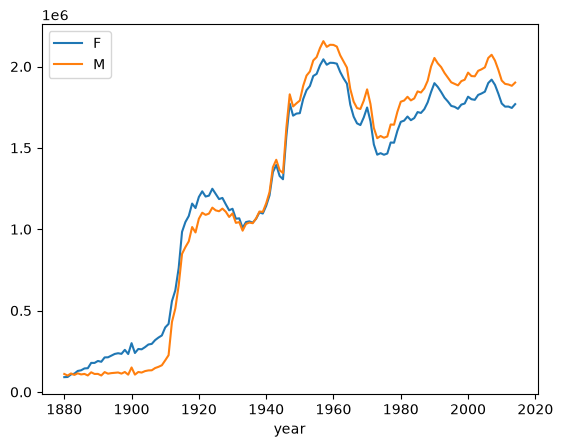

In [156]:
# 선그래프 생성하기
total_births.plot()
plt.show()

In [157]:
# 그래프의 가로 세로 비율 적용
plt.rcParams['figure.figsize'] = (14, 6)

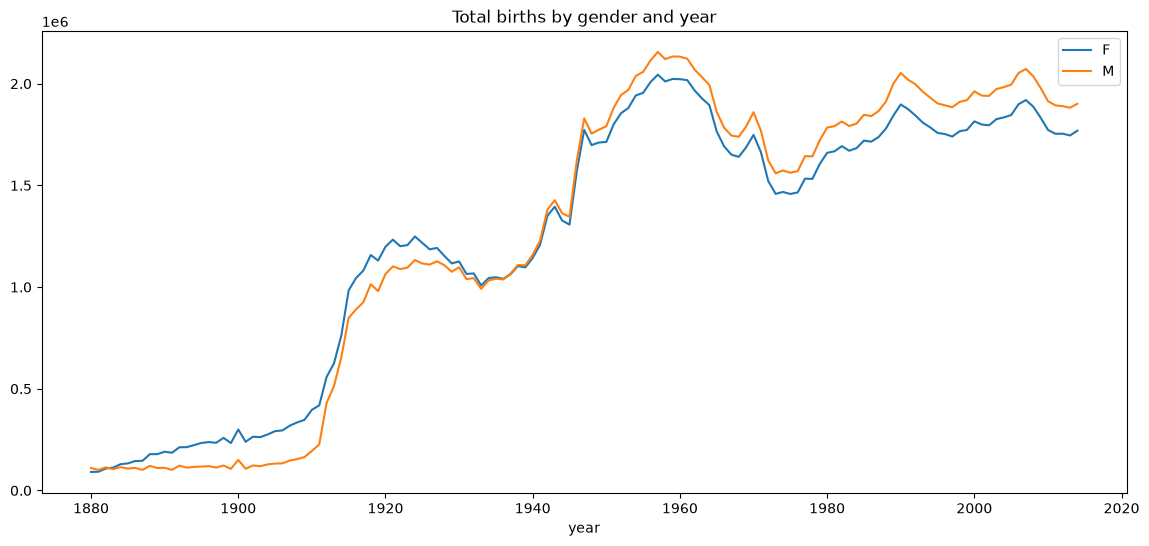

In [158]:
total_births.plot(
    title='Total births by gender and year'
)
plt.show()

----
#### 순수코딩

In [159]:
# 연도와 성별로 정렬
names2 = names.sort_values(by=['gender', 'year'])
names2.head()

,name,gender,births,year,id
0,Mary,F,7065,1880,1
1,Anna,F,2604,1880,2
2,Emma,F,2003,1880,3
3,Elizabeth,F,1939,1880,4
4,Minnie,F,1746,1880,5


In [171]:
female = []
male = []

for gender, births, year in zip(names2.gender, names2.births, names2.year):
    if gender == 'F':
        try:
            female[year-1880] += births
        except:
            female.append(births)
    else:
        try:
            male[year-1880] += births
        except:
            male.append(births)

print(female)
print(male)

[90993, 91954, 107850, 112321, 129022, 133055, 144535, 145982, 178627, 178366, 190377, 185482, 212346, 212906, 222922, 233630, 237920, 234202, 258770, 233023, 299828, 239348, 264077, 261973, 275366, 291623, 295303, 318566, 334313, 347228, 396501, 418299, 558103, 624513, 761548, 983867, 1044316, 1081275, 1157641, 1130131, 1198283, 1232993, 1200913, 1206330, 1248869, 1217342, 1185304, 1192330, 1153109, 1116415, 1125761, 1064492, 1066994, 1007703, 1044039, 1048428, 1040192, 1063872, 1103272, 1096511, 1143325, 1207919, 1350545, 1395075, 1327104, 1307028, 1571177, 1772644, 1697814, 1710825, 1713180, 1800042, 1854698, 1880326, 1941682, 1954664, 2007506, 2044160, 2010884, 2023044, 2022093, 2017316, 1966548, 1927217, 1894594, 1765001, 1691868, 1650764, 1640103, 1686941, 1748147, 1663475, 1521185, 1458139, 1467413, 1457699, 1465096, 1532997, 1531658, 1605051, 1659933, 1667465, 1692678, 1670061, 1682973, 1720036, 1714664, 1737891, 1779839, 1843105, 1897709, 1874434, 1843304, 1808379, 1785074, 17

---
### groupby 사용

In [174]:
# groupby 사용한 년도별 합계

names.groupby(['year']).births.sum()

year
1880     201484
1881     192699
1882     221533
1883     216950
1884     243467
         ...   
2010    3686589
2011    3646730
2012    3643336
2013    3626802
2014    3670151
Name: births, Length: 135, dtype: int64

In [175]:
# groupby를 사용한 년도별, 성별 합계
names.groupby(['year', 'gender']).births.sum()

year  gender
1880  F           90993
      M          110491
1881  F           91954
      M          100745
1882  F          107850
                 ...   
2012  M         1889414
2013  F         1745339
      M         1881463
2014  F         1768775
      M         1901376
Name: births, Length: 270, dtype: int64

In [179]:
names.groupby(['year', 'gender']).births.sum().unstack('gender')

gender,F,M
year,,
1880,90993,110491
1881,91954,100745
1882,107850,113683
1883,112321,104629
1884,129022,114445
...,...,...
2010,1772738,1913851
2011,1753500,1893230
2012,1753922,1889414


----
#### pivot 사용

In [180]:
names.pivot_table(
    'births',
    index='year',
    columns='gender',
    aggfunc='sum'
)

gender,F,M
year,,
1880,90993,110491
1881,91954,100745
1882,107850,113683
1883,112321,104629
1884,129022,114445
...,...,...
2010,1772738,1913851
2011,1753500,1893230
2012,1753922,1889414


---
#### 새로운 csv로 저장하기

In [182]:
# 필요한 컬럼만으로 새로운 DataFrame 만들기

names2 = pd.DataFrame(names, columns=['name', 'year', 'gender', 'births'])
names2.head()

,name,year,gender,births
0,Mary,1880,F,7065
1,Anna,1880,F,2604
2,Emma,1880,F,2003
3,Elizabeth,1880,F,1939
4,Minnie,1880,F,1746


In [185]:
# csv형식으로 저장하기
names2.to_csv('../Data/birth_names.csv',index=False)

In [186]:
pd.read_csv("../Data/birth_names.csv").head()

,name,year,gender,births
0,Mary,1880,F,7065
1,Anna,1880,F,2604
2,Emma,1880,F,2003
3,Elizabeth,1880,F,1939
4,Minnie,1880,F,1746
